### Exploration des données — Fiabilité des liaisons TGV

**Problématique :** Quelles sont les liaisons TGV les plus touchées par les retards à l'arrivée ?

**Objectif :** Analyser les taux de retard par liaison, leur évolution mensuelle et leur prévisibilité.

**Données :** [Régularité mensuelle TGV](https://ressources.data.sncf.com/explore/dataset/regularite-mensuelle-tgv-aqst/information/)

## 1. Importation des librairies

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

In [4]:
# Préalable
print("Python utilisé :", sys.executable)
print("Dossier de travail :", Path.cwd())
print("Fichiers CSV :", list(Path("../data/raw").glob("*.csv")))

Python utilisé : /home/emman/projets/RailInsight-SNCF/.venv/bin/python
Dossier de travail : /home/emman/projets/RailInsight-SNCF/notebooks
Fichiers CSV : [PosixPath('../data/raw/regularite-mensuelle-tgv-aqst.csv')]


## 2. Les données

In [11]:
# chargement de la base
df = pd.read_csv("../data/raw/regularite-mensuelle-tgv-aqst.csv", sep=";")
print("Lignes et colonnes :", df.shape)

Lignes et colonnes : (12907, 26)


In [12]:
# Structure générale du jeu de données
print("Dimensions :", df.shape)

print("\nInformations générales :")
df.info()

Dimensions : (12907, 26)

Informations générales :
<class 'pandas.DataFrame'>
RangeIndex: 12907 entries, 0 to 12906
Data columns (total 26 columns):
 #   Column                                                                                       Non-Null Count  Dtype  
---  ------                                                                                       --------------  -----  
 0   Date                                                                                         12907 non-null  str    
 1   Service                                                                                      12907 non-null  str    
 2   Gare de départ                                                                               12907 non-null  str    
 3   Gare d'arrivée                                                                               12907 non-null  str    
 4   Durée moyenne du trajet                                                                      12907 non-null  int64

## 3. Statistiques descriptives et couverture des données

In [16]:
# Statistiques descriptives des variables numériques
display(df.describe().T.round(2))

# Période couverte
print("Date minimale :", df["Date"].min())
print("Date maximale :", df["Date"].max())

# Répartition des observations par service
display(df["Service"].value_counts().to_frame("Nombre de lignes"))

,count,mean,std,min,25%,50%,75%,max
Durée moyenne du trajet,12907.0,170.69,87.73,0.00,99.00,163.00,223.00,786.00
Nombre de circulations prévues,12907.0,273.44,184.12,0.00,151.00,231.00,365.00,1104.00
Nombre de trains annulés,12907.0,8.27,21.81,0.00,0.00,2.00,7.00,297.00
Commentaire annulations,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nombre de trains en retard au départ,12907.0,86.70,88.75,0.00,22.00,52.00,127.00,598.00
Retard moyen des trains en retard au départ,12907.0,12.60,11.58,0.00,6.43,10.70,16.23,316.19
Retard moyen de tous les trains au départ,12907.0,3.22,5.02,-229.27,1.25,2.40,4.09,115.05
Commentaire retards au départ,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nombre de trains en retard à l'arrivée,12907.0,38.87,32.45,0.00,16.00,30.00,53.00,376.00
Retard moyen des trains en retard à l'arrivée,12907.0,35.62,15.61,-40.11,26.09,33.90,42.91,299.60


Date minimale : 2018-01
Date maximale : 2026-09


,Nombre de lignes
Service,
National,11339
International,1568


L'analyse descriptive porte sur 12 907 observations, réparties entre janvier 2018 et septembre 2026. Le service national est largement représenté avec 11 339 observations, contre 1 568 pour le service international. En moyenne, chaque observation compte 273 circulations prévues, dont environ 8 annulations et 39 trains en retard à l'arrivée. On observe également une forte variabilité entre les liaisons, notamment dans le nombre de circulations prévues, qui varie de 0 à 1 104. Ces premiers résultats montrent l'importance de tenir compte du volume de trains et de la période étudiée pour comparer correctement les taux de retard des différentes liaisons TGV.

## 4. Vérification de la qualité des données

In [19]:
# 1. Valeurs manquantes
manquants = pd.DataFrame({
    "Nombre": df.isna().sum(),
    "Pourcentage (%)": (df.isna().mean() * 100).round(2)
})

display(manquants[manquants["Nombre"] > 0])

,Nombre,Pourcentage (%)
Commentaire annulations,12907,100.00
Commentaire retards au départ,12907,100.00
Commentaire retards à l'arrivée,12209,94.59


In [20]:
# 2. Doublons
print("Doublons complets :", df.duplicated().sum())

cles = ["Date", "Service", "Gare de départ", "Gare d'arrivée"]
print("Doublons mois-service-liaison :", df.duplicated(subset=cles).sum())

Doublons complets : 0
Doublons mois-service-liaison : 0


In [21]:
# 3. Cohérence des effectifs
circules = df["Nombre de circulations prévues"] - df["Nombre de trains annulés"]

print("Annulations > trains prévus :",
      (df["Nombre de trains annulés"] > df["Nombre de circulations prévues"]).sum())

print("Retards à l'arrivée > trains circulés :",
      (df["Nombre de trains en retard à l'arrivée"] > circules).sum())

print("Durées de trajet non positives :",
      (df["Durée moyenne du trajet"] <= 0).sum())

Annulations > trains prévus : 63
Retards à l'arrivée > trains circulés : 63
Durées de trajet non positives : 73


L'analyse de la qualité des données révèle que les valeurs manquantes concernent uniquement les trois variables de commentaires, dont deux sont entièrement vides et une présente 94,59 % de valeurs manquantes. Par ailleurs, aucun doublon n'a été détecté, que ce soit sur l'ensemble des variables ou sur la combinaison mois-service-liaison. Toutefois, les contrôles de cohérence mettent en évidence 63 observations où les annulations dépassent les circulations prévues, 63 où les retards à l'arrivée dépassent le nombre de trains circulés et 73 où la durée moyenne du trajet est nulle.

## 5. les anomalies

In [24]:
# Identification des observations présentant des anomalies
anomalie_annulation = (
    df["Nombre de trains annulés"] > df["Nombre de circulations prévues"]
)

anomalie_retard = (
    df["Nombre de trains en retard à l'arrivée"] > circules
)

anomalie_duree = df["Durée moyenne du trajet"] <= 0

In [27]:
# Nombre d'observations concernées
anomalies = anomalie_annulation | anomalie_retard | anomalie_duree

print("Total de lignes présentant au moins une anomalie :", anomalies.sum())

Total de lignes présentant au moins une anomalie : 73


In [26]:
# Examination des observations concernées
colonnes = [
    "Date", "Service", "Gare de départ", "Gare d'arrivée",
    "Durée moyenne du trajet", "Nombre de circulations prévues",
    "Nombre de trains annulés", "Nombre de trains en retard à l'arrivée"
]

display(df.loc[anomalies, colonnes].head(10))

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard à l'arrivée
3406,2020-04,National,PARIS MONTPARNASSE,ST MALO,0,0,8,0
3407,2020-04,National,PARIS MONTPARNASSE,TOURS,0,0,9,0
3409,2020-04,National,NANTES,STRASBOURG,0,0,2,0
3411,2020-04,National,PARIS NORD,DOUAI,0,0,12,0
3412,2020-04,National,DUNKERQUE,PARIS NORD,0,0,15,0
3414,2020-04,National,MARSEILLE ST CHARLES,TOURCOING,0,0,1,0
3415,2020-04,National,LYON PART DIEU,MARNE LA VALLEE,0,0,19,0
3416,2020-04,National,MARNE LA VALLEE,MARSEILLE ST CHARLES,0,0,14,0
3417,2020-04,National,MARSEILLE ST CHARLES,MARNE LA VALLEE,0,0,13,0
3418,2020-04,National,PARIS LYON,AIX EN PROVENCE TGV,0,0,17,0


In [28]:
# Répartition des anomalies par mois
print(df.loc[anomalies, "Date"].value_counts().sort_index())

Date
2020-04    50
2020-05     9
2020-06     4
2020-08     2
2020-09     2
2020-10     2
2020-11     2
2020-12     2
Name: count, dtype: int64


Les 73 observations présentant des anomalies sont toutes concentrées en 2020, principalement en avril (50 observations), soit environ 68,5 % du total. Les anomalies diminuent fortement à partir de mai et deviennent ponctuelles jusqu'en décembre.


## 5. Analyse univariée des données

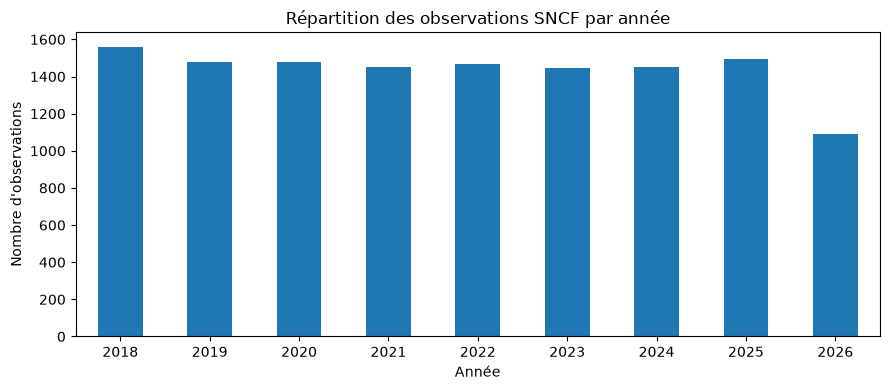

In [ ]:
# Visualisation des observations par année

# Nombre d'observations par année
observations_annee = (
    df["Date"]
    .str[:4]
    .value_counts()
    .sort_index()
)

# Visualisation
observations_annee.plot(
    kind="bar",
    figsize=(9, 4),
)

plt.title("Répartition des observations SNCF par année")
plt.xlabel("Année")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plt.title("Répartition des observations SNCF par année")
plt.xlabel("Année")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

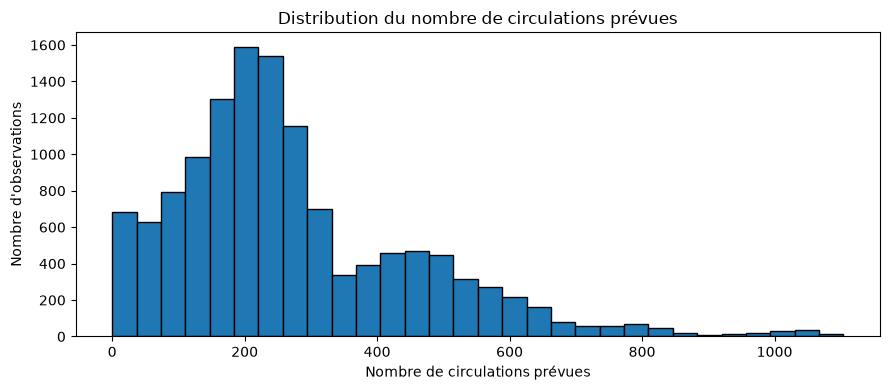

In [35]:
# Distribution des circulations prévues par liaison et par mois
df["Nombre de circulations prévues"].plot(
    kind="hist",
    bins=30,
    figsize=(9, 4),
    edgecolor="black"
)

plt.title("Distribution du nombre de circulations prévues")
plt.xlabel("Nombre de circulations prévues")
plt.ylabel("Nombre d'observations")
plt.tight_layout()
plt.show()

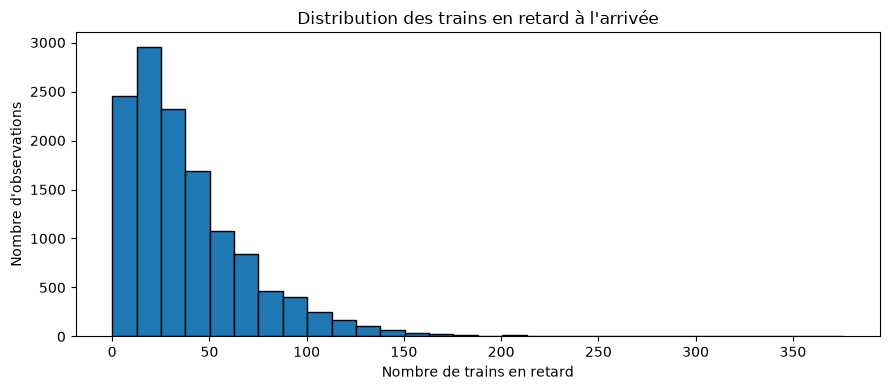

In [36]:
# Distribution du nombre de trains en retard à l'arrivée
df["Nombre de trains en retard à l'arrivée"].plot(
    kind="hist",
    bins=30,
    figsize=(9, 4),
    edgecolor="black"
)

plt.title("Distribution des trains en retard à l'arrivée")
plt.xlabel("Nombre de trains en retard")
plt.ylabel("Nombre d'observations")
plt.tight_layout()
plt.show()

La répartition annuelle des observations est relativement stable entre 2018 et 2025, tandis que 2026 est incomplète (données jusqu’en septembre). Les distributions des trains prévus et des retards à l’arrivée sont asymétriques à droite : la majorité des observations compte entre 150 et 300 trains prévus et entre 0 et 60 retards mensuels, avec quelques valeurs extrêmes. Ces disparités reflètent la nécessité de privilégier les taux de retard plutôt que les volumes absolus pour comparer leur régularité.

## 6 - Analyse bivariée

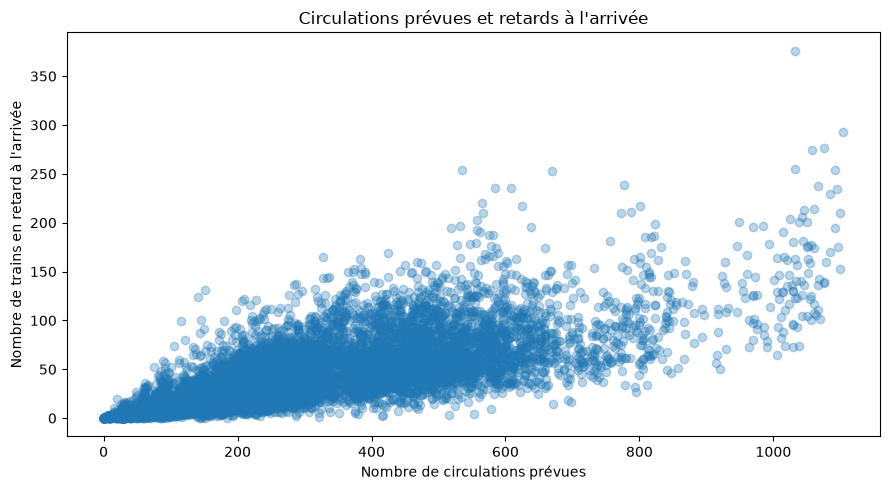

In [37]:
# Relation entre les circulations prévues et les retards à l'arrivée
plt.figure(figsize=(9, 5))

plt.scatter(
    df["Nombre de circulations prévues"],
    df["Nombre de trains en retard à l'arrivée"],
    alpha=0.3
)

plt.title("Circulations prévues et retards à l'arrivée")
plt.xlabel("Nombre de circulations prévues")
plt.ylabel("Nombre de trains en retard à l'arrivée")
plt.tight_layout()
plt.show()

In [40]:
# Corrélation entre les circulations prévues et les retards à l'arrivée
x = df["Nombre de circulations prévues"]
y = df["Nombre de trains en retard à l'arrivée"]

print("Corrélation de Pearson :", round(x.corr(y, method="pearson"), 3))
print("Corrélation de Spearman :", round(x.corr(y, method="spearman"), 3))

Corrélation de Pearson : 0.758
Corrélation de Spearman : 0.804


Le nuage de points révèle une relation positive relativement forte entre le nombre de circulations prévues et le nombre de trains en retard à l'arrivée, confirmée par les coefficients de Pearson (0,758) et de Spearman (0,804). La dispersion augmente toutefois avec le volume de circulation. Cette association ne traduit pas nécessairement un lien de causalité : les liaisons les plus fréquentées enregistrent davantage de retards en valeur absolue, sans être forcément moins régulières.

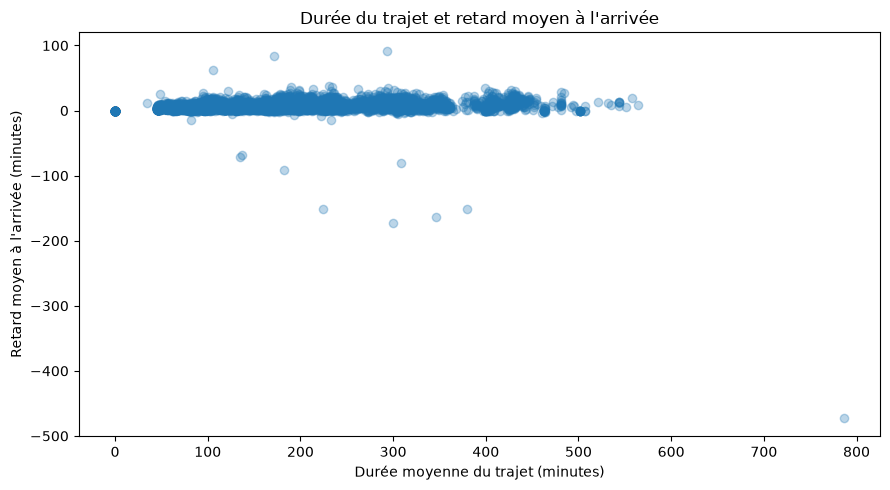

In [41]:
# Relation entre la durée du trajet et le retard moyen à l'arrivée
plt.figure(figsize=(9, 5))

plt.scatter(
    df["Durée moyenne du trajet"],
    df["Retard moyen de tous les trains à l'arrivée"],
    alpha=0.3
)

plt.title("Durée du trajet et retard moyen à l'arrivée")
plt.xlabel("Durée moyenne du trajet (minutes)")
plt.ylabel("Retard moyen à l'arrivée (minutes)")
plt.tight_layout()
plt.show()

In [42]:
# Corrélations entre la durée du trajet et le retard moyen
x = df["Durée moyenne du trajet"]
y = df["Retard moyen de tous les trains à l'arrivée"]

print("Pearson :", round(x.corr(y, method="pearson"), 3))
print("Spearman :", round(x.corr(y, method="spearman"), 3))

Pearson : 0.171
Spearman : 0.383


Le nuage de points suggère une légère augmentation du retard moyen avec la durée du trajet, malgré une forte dispersion. Les corrélations de Pearson (0,171) et de Spearman (0,383) confirment une association positive limitée. Quelques valeurs extrêmes sont également observées.

Intensité des retards à l'arrivée

In [43]:
# Statistiques descriptives des retards selon leur gravité
colonnes_retard = [
    "Nombre trains en retard > 15min",
    "Nombre trains en retard > 30min",
    "Nombre trains en retard > 60min"
]

display(df[colonnes_retard].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Nombre trains en retard > 15min,12907.0,28.10,23.91,0.0,11.0,22.0,38.0,312.0
Nombre trains en retard > 30min,12907.0,13.33,13.03,-44.0,4.0,10.0,18.0,202.0
Nombre trains en retard > 60min,12907.0,5.49,6.39,0.0,1.0,3.0,7.0,77.0


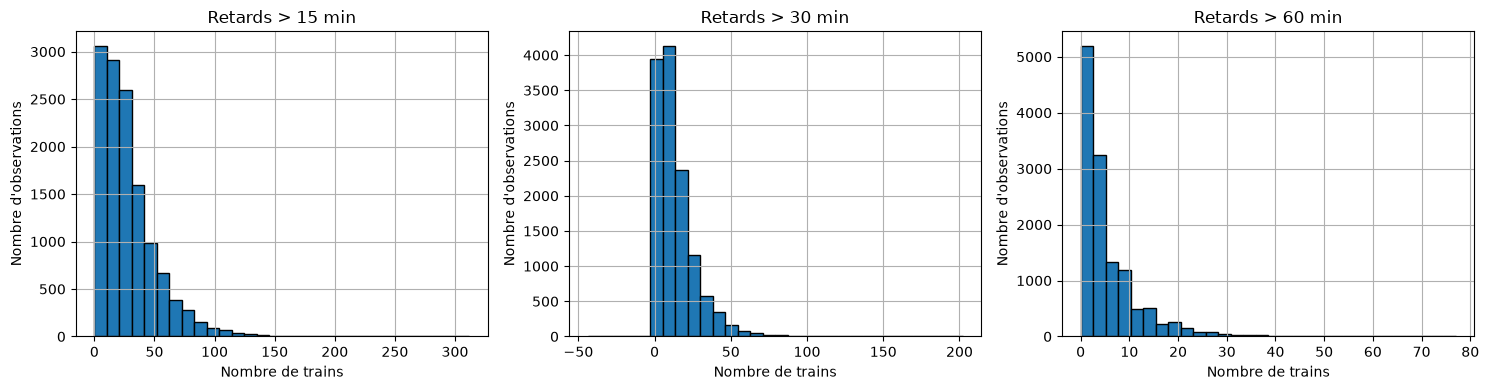

In [44]:
# Distribution des retards de plus de 15, 30 et 60 minutes
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

seuils = [15, 30, 60]

for ax, colonne, seuil in zip(axes, colonnes_retard, seuils):
    df[colonne].hist(bins=30, ax=ax, edgecolor="black")
    ax.set_title(f"Retards > {seuil} min")
    ax.set_xlabel("Nombre de trains")
    ax.set_ylabel("Nombre d'observations")

plt.tight_layout()
plt.show()

In [45]:
# Corrélations entre les différents seuils de retard
display(df[colonnes_retard].corr(method="pearson").round(3))

,Nombre trains en retard > 15min,Nombre trains en retard > 30min,Nombre trains en retard > 60min
Nombre trains en retard > 15min,1.000,0.922,0.798
Nombre trains en retard > 30min,0.922,1.000,0.797
Nombre trains en retard > 60min,0.798,0.797,1.000


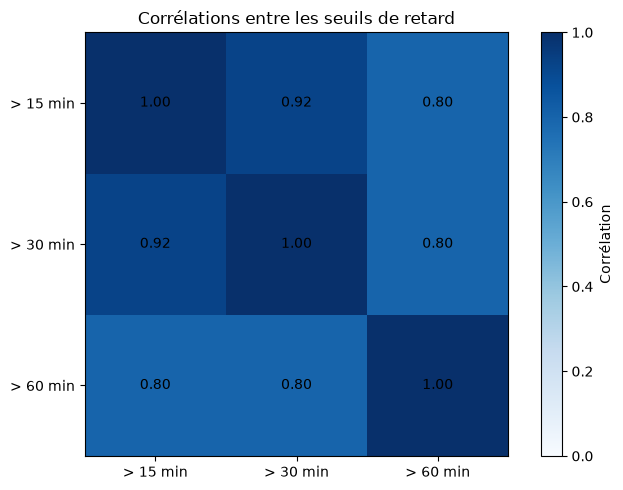

In [46]:
# Matrice de corrélation des retards selon leur gravité
correlations = df[colonnes_retard].corr()

plt.figure(figsize=(7, 5))
plt.imshow(correlations, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Corrélation")

plt.xticks(range(3), ["> 15 min", "> 30 min", "> 60 min"])
plt.yticks(range(3), ["> 15 min", "> 30 min", "> 60 min"])

for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{correlations.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.title("Corrélations entre les seuils de retard")
plt.tight_layout()
plt.show()

L'analyse des retards à l'arrivée montre que leur fréquence diminue lorsque le seuil de retard augmente. En moyenne, on observe 28,10 trains ayant plus de 15 minutes de retard par liaison et par mois, contre 13,33 pour les retards de plus de 30 minutes et 5,49 pour ceux dépassant 60 minutes. Les distributions sont fortement asymétriques à droite, avec quelques observations présentant des retards particulièrement élevés. Par ailleurs, les corrélations entre les différents seuils sont fortes, notamment entre les retards de plus de 15 et 30 minutes (0,922).

## 7 — Analyse des taux de retard à l'arrivée

In [47]:
# Préparation des observations exploitables pour les taux
analyse = df.copy()

analyse["Trains circulés"] = (
    analyse["Nombre de circulations prévues"]
    - analyse["Nombre de trains annulés"]
)

valides = (
    (analyse["Nombre de circulations prévues"] > 0)
    & (analyse["Nombre de trains annulés"] >= 0)
    & (analyse["Trains circulés"] > 0)
    & (analyse["Nombre de trains en retard à l'arrivée"] >= 0)
    & (analyse["Nombre de trains en retard à l'arrivée"] <= analyse["Trains circulés"])
)

analyse = analyse.loc[valides].copy()

analyse["Taux de retard (%)"] = (
    100 * analyse["Nombre de trains en retard à l'arrivée"]
    / analyse["Trains circulés"]
)

print("Observations conservées :", len(analyse))
print("Observations écartées :", len(df) - len(analyse))

Observations conservées : 12834
Observations écartées : 73


In [48]:
# Statistiques descriptives des taux de retard
display(analyse["Taux de retard (%)"].describe().round(2))

count    12834.00
mean        14.93
std          8.44
min          0.00
25%          9.38
50%         13.36
75%         18.70
max        100.00
Name: Taux de retard (%), dtype: float64

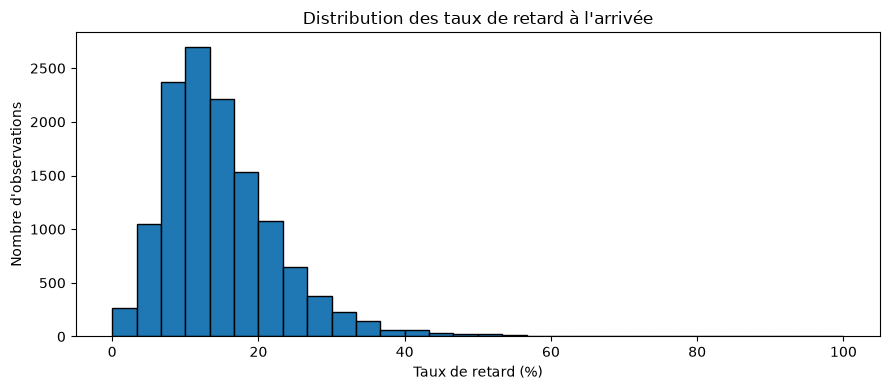

In [49]:
# Distribution des taux de retard à l'arrivée
analyse["Taux de retard (%)"].plot(
    kind="hist",
    bins=30,
    figsize=(9, 4),
    edgecolor="black"
)

plt.title("Distribution des taux de retard à l'arrivée")
plt.xlabel("Taux de retard (%)")
plt.ylabel("Nombre d'observations")
plt.tight_layout()
plt.show()

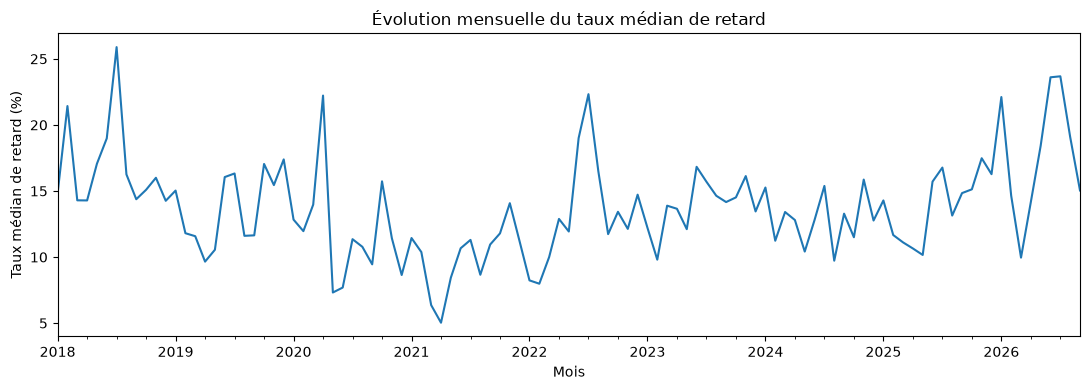

In [50]:
# Évolution mensuelle du taux médian de retard
analyse["Mois"] = pd.to_datetime(analyse["Date"], format="%Y-%m")

taux_mensuel = analyse.groupby("Mois")["Taux de retard (%)"].median()

taux_mensuel.plot(figsize=(11, 4))

plt.title("Évolution mensuelle du taux médian de retard")
plt.xlabel("Mois")
plt.ylabel("Taux médian de retard (%)")
plt.tight_layout()
plt.show()

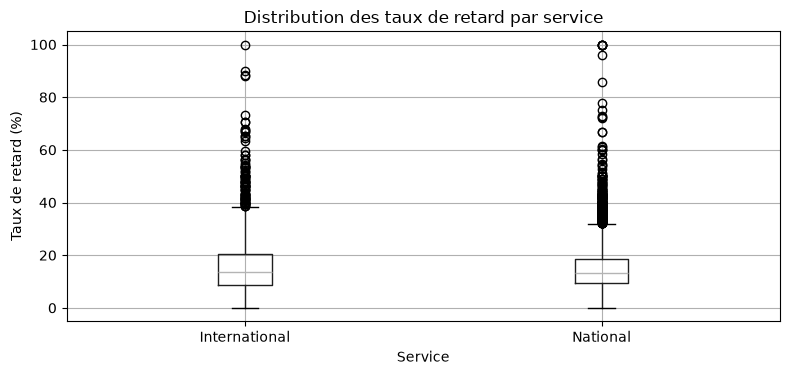

In [51]:
# Comparaison des taux de retard selon le service
analyse.boxplot(
    column="Taux de retard (%)",
    by="Service",
    figsize=(8, 4)
)

plt.suptitle("")
plt.title("Distribution des taux de retard par service")
plt.xlabel("Service")
plt.ylabel("Taux de retard (%)")
plt.tight_layout()
plt.show()

L'analyse des taux de retard porte sur **12 834 observations**, après l'exclusion de 73 lignes présentant des incohérences dans les effectifs de circulation. Le taux moyen de retard à l'arrivée est de 14,93 %, contre une médiane de 13,36 %. La majorité des observations présente des taux relativement modérés, mais certaines atteignent 100 %. Par ailleurs, l'évolution mensuelle montre des fluctuations importantes entre 2018 et 2026, sans tendance régulière clairement identifiable. Enfin, les distributions des services national et international restent assez proches, même si le service international semble présenter une dispersion légèrement plus importante. Ces résultats montrent l'intérêt d'approfondir l'analyse par liaison et par période afin d'identifier les lignes les moins régulières.

Comparaison de la régularité des liaisons TGV

Nombre de liaisons : 146


,Nombre de mois
count,146.00
mean,87.90
std,36.23
min,3.00
25%,104.00
50%,104.00
75%,105.00
max,105.00


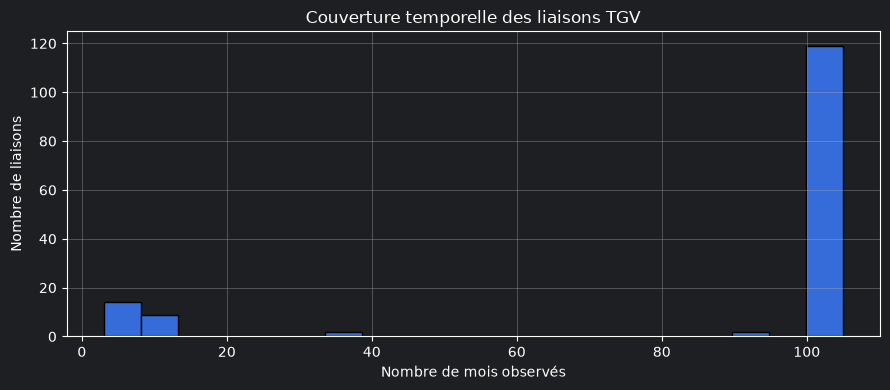

In [52]:
# Couverture temporelle des liaisons TGV
cles_liaison = ["Service", "Gare de départ", "Gare d'arrivée"]

couverture = (
    analyse.groupby(cles_liaison)["Mois"]
    .nunique()
)

print("Nombre de liaisons :", len(couverture))
display(couverture.describe().round(2).to_frame("Nombre de mois"))

# Distribution du nombre de mois disponibles
couverture.hist(bins=20, figsize=(9, 4), edgecolor="black")

plt.title("Couverture temporelle des liaisons TGV")
plt.xlabel("Nombre de mois observés")
plt.ylabel("Nombre de liaisons")
plt.tight_layout()
plt.show()

In [53]:
# Agrégation des retards et des circulations par liaison
liaisons = (
    analyse.groupby(cles_liaison)
    .agg(
        mois_observes=("Mois", "nunique"),
        trains_circules=("Trains circulés", "sum"),
        trains_retard=("Nombre de trains en retard à l'arrivée", "sum")
    )
    .reset_index()
)

# Calcul du taux de retard pondéré par le nombre de trains
liaisons["Taux de retard (%)"] = (
    100 * liaisons["trains_retard"] / liaisons["trains_circules"]
)

display(
    liaisons.sort_values("Taux de retard (%)", ascending=False)
    .head(15)
    .round(2)
)

,Service,Gare de départ,Gare d'arrivée,mois_observes,trains_circules,trains_retard,Taux de retard (%)
9,International,MACON LOCHE,PARIS LYON,3,181,97,53.59
2,International,CHAMBERY CHALLES LES EAUX,PARIS LYON,3,267,106,39.70
6,International,ITALIE,PARIS LYON,100,6897,2278,33.03
8,International,LYON PART DIEU,MARSEILLE ST CHARLES,3,145,47,32.41
27,International,STRASBOURG,PARIS EST,3,718,230,32.03
43,National,CHAMBERY CHALLES LES EAUX,PARIS LYON,104,21537,5846,27.14
55,National,LYON PART DIEU,LILLE,105,28919,7650,26.45
61,National,MACON LOCHE,PARIS LYON,105,22163,5805,26.19
56,National,LYON PART DIEU,MARNE LA VALLEE,104,31206,7925,25.40
16,International,PARIS EST,STUTTGART,104,12353,2911,23.57


count      146.00
mean     23445.44
std      18994.31
min        145.00
25%       9540.50
50%      21203.50
75%      30634.25
max      91762.00
Name: trains_circules, dtype: float64

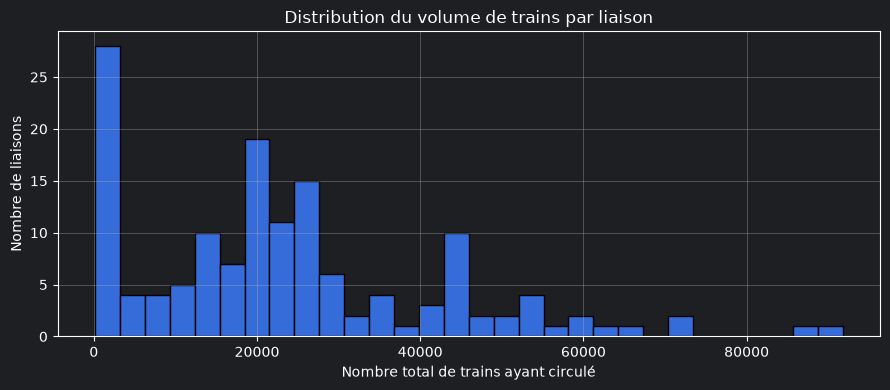

In [54]:
# Distribution du volume total de trains par liaison
display(liaisons["trains_circules"].describe().round(2))

liaisons["trains_circules"].hist(
    bins=30,
    figsize=(9, 4),
    edgecolor="black"
)

plt.title("Distribution du volume de trains par liaison")
plt.xlabel("Nombre total de trains ayant circulé")
plt.ylabel("Nombre de liaisons")
plt.tight_layout()
plt.show()

L'analyse porte sur **146 liaisons TGV**, dont la couverture temporelle varie de 3 à 105 mois, avec une moyenne de 87,9 mois. La majorité des liaisons dispose d'environ 104 à 105 mois d'observation, tandis que quelques-unes ne sont présentes que sur une courte période. Par ailleurs, les volumes de circulation sont très différents selon les liaisons, certaines comptant quelques centaines de trains contre plusieurs dizaines de milliers pour d'autres. Ces différences montrent qu'il est nécessaire de comparer les taux de retard sur une période commune et de tenir compte du volume de trains pour obtenir un classement pertinent.

## 9. Classement des liaisons TGV les plus en retard

In [55]:
# Sélection des observations de l'année 2025
donnees_2025 = analyse[analyse["Mois"].dt.year == 2025].copy()

# Calcul des indicateurs par liaison
cles = ["Service", "Gare de départ", "Gare d'arrivée"]

classement = (
    donnees_2025.groupby(cles)
    .agg(
        mois_observes=("Mois", "nunique"),
        trains_circules=("Trains circulés", "sum"),
        trains_retard=("Nombre de trains en retard à l'arrivée", "sum"),
        trains_prevus=("Nombre de circulations prévues", "sum"),
        trains_annules=("Nombre de trains annulés", "sum")
    )
    .reset_index()
)

classement["Taux de retard (%)"] = (
    100 * classement["trains_retard"] / classement["trains_circules"]
)

# Sélection des liaisons suffisamment représentées
classement = classement[
    (classement["mois_observes"] >= 10)
    & (classement["trains_circules"] >= 500)
].copy()

top10 = classement.nlargest(10, "Taux de retard (%)")

display(top10.round(2))

,Service,Gare de départ,Gare d'arrivée,mois_observes,trains_circules,trains_retard,trains_prevus,trains_annules,Taux de retard (%)
14,International,PARIS EST,STUTTGART,12,1429,808,1460,31,56.54
6,International,ITALIE,PARIS LYON,12,838,284,860,22,33.89
12,International,PARIS EST,FRANCFORT,12,2044,645,2092,48,31.56
58,National,MACON LOCHE,PARIS LYON,12,2534,775,2544,10,30.58
40,National,CHAMBERY CHALLES LES EAUX,PARIS LYON,12,2775,802,2790,15,28.90
53,National,LYON PART DIEU,MARNE LA VALLEE,12,4143,1112,4174,31,26.84
52,National,LYON PART DIEU,LILLE,12,4034,1030,4074,40,25.53
55,National,LYON PART DIEU,MONTPELLIER,12,3242,766,3251,9,23.63
54,National,LYON PART DIEU,MARSEILLE ST CHARLES,12,5722,1350,5756,34,23.59
59,National,MARNE LA VALLEE,LYON PART DIEU,12,4712,1088,4738,26,23.09


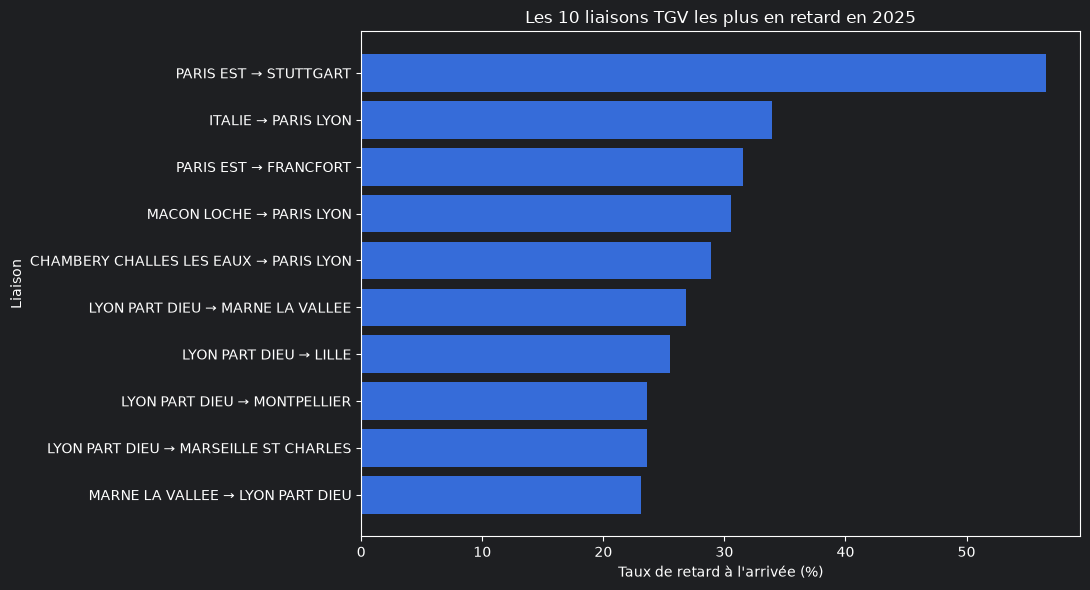

In [56]:
# Visualisation des 10 liaisons présentant les taux de retard les plus élevés
top10 = top10.copy()

top10["Liaison"] = (
    top10["Gare de départ"] + " → " + top10["Gare d'arrivée"]
)

plt.figure(figsize=(11, 6))

plt.barh(
    top10["Liaison"][::-1],
    top10["Taux de retard (%)"][::-1]
)

plt.title("Les 10 liaisons TGV les plus en retard en 2025")
plt.xlabel("Taux de retard à l'arrivée (%)")
plt.ylabel("Liaison")
plt.tight_layout()
plt.show()

Le classement des liaisons TGV en 2025 fait ressortir **Paris Est → Stuttgart** comme la liaison présentant le taux de retard à l'arrivée le plus élevé, avec environ 56 %. Elle est suivie par Italie → Paris Lyon (environ 34 %) et Paris Est → Francfort (environ 32 %). Plusieurs liaisons nationales figurent également parmi les dix premières, notamment Mâcon Loché → Paris Lyon et Chambéry-Challes-les-Eaux → Paris Lyon. Ce classement repose sur les liaisons comptant au moins dix mois d'observation et 500 trains circulés en 2025, afin de limiter l'influence des effectifs trop faibles.

Évolution mensuelle des 5 liaisons les plus en retard

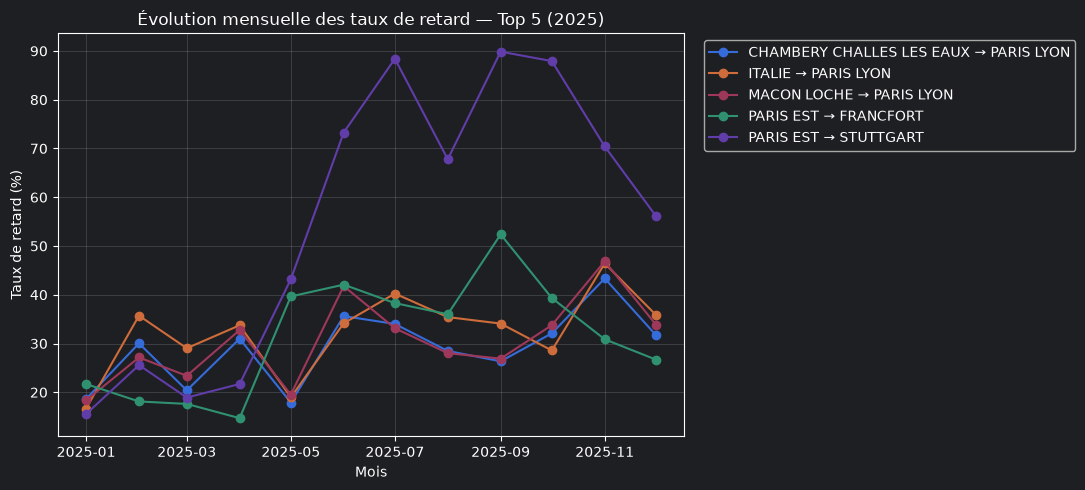

In [57]:
# Sélection des cinq premières liaisons du classement
top5 = top10.head(5)[cles]

evolution = donnees_2025.merge(top5, on=cles, how="inner").copy()

evolution["Liaison"] = (
    evolution["Gare de départ"] + " → " + evolution["Gare d'arrivée"]
)

# Visualisation de l'évolution mensuelle des taux de retard
plt.figure(figsize=(11, 5))

for liaison, groupe in evolution.groupby("Liaison"):
    groupe = groupe.sort_values("Mois")
    plt.plot(
        groupe["Mois"],
        groupe["Taux de retard (%)"],
        marker="o",
        label=liaison
    )

plt.title("Évolution mensuelle des taux de retard — Top 5 (2025)")
plt.xlabel("Mois")
plt.ylabel("Taux de retard (%)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

L'évolution mensuelle des cinq liaisons les plus en retard en 2025 montre des variations importantes au cours de l'année. La liaison Paris Est → Stuttgart se distingue particulièrement à partir du mois de mai, avec des taux atteignant près de 90 % durant certains mois. Les autres liaisons présentent des taux généralement compris entre 15 % et 45 %, avec quelques pics ponctuels, notamment sur Paris Est → Francfort. Ces résultats montrent que les retards ne sont pas constants dans le temps et que leur évolution varie selon les liaisons.

Comparaison entre les retards et les annulations

Corrélation de Pearson : 0.151


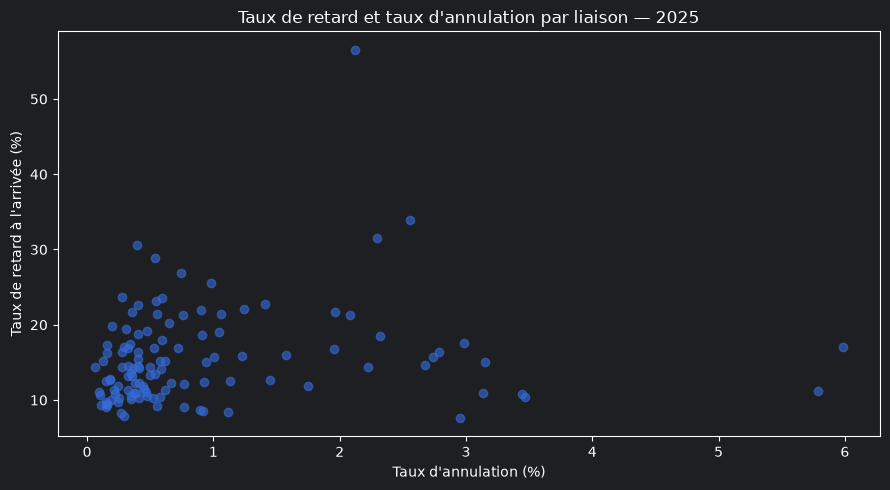

In [58]:
# Calcul du taux d'annulation par liaison
classement["Taux d'annulation (%)"] = (
    100 * classement["trains_annules"] / classement["trains_prevus"]
)

# Corrélation entre les taux de retard et d'annulation
correlation = classement["Taux de retard (%)"].corr(
    classement["Taux d'annulation (%)"]
)

print("Corrélation de Pearson :", round(correlation, 3))

# Visualisation de la relation entre les deux taux
plt.figure(figsize=(9, 5))

plt.scatter(
    classement["Taux d'annulation (%)"],
    classement["Taux de retard (%)"],
    alpha=0.6
)

plt.title("Taux de retard et taux d'annulation par liaison — 2025")
plt.xlabel("Taux d'annulation (%)")
plt.ylabel("Taux de retard à l'arrivée (%)")
plt.tight_layout()
plt.show()

L'analyse de la relation entre les taux de retard et d'annulation des liaisons TGV en 2025 met en évidence une **faible corrélation positive**, avec un coefficient de Pearson de 0,151. Le nuage de points montre que la majorité des liaisons présente un taux d'annulation inférieur à 1,5 %, mais des taux de retard très variables. Certaines liaisons enregistrent ainsi de nombreux retards malgré un faible niveau d'annulation.

## CONCLUSION GENERALE DE EDA

L'analyse exploratoire des données SNCF, couvrant la période de janvier 2018 à septembre 2026, a permis d'étudier la régularité des liaisons TGV. Après exclusion des 73 observations présentant des incohérences, le taux moyen de retard à l'arrivée s'établit à 14,93 % par observation liaison-mois. Les résultats mettent en évidence des différences importantes selon les liaisons et les périodes. En 2025, **Paris Est → Stuttgart** présente notamment le taux de retard le plus élevé parmi les liaisons retenues, avec environ 56 %. Par ailleurs, la faible corrélation entre les taux de retard et d'annulation (0,151) montre que ces deux indicateurs doivent être examinés séparément. Ces résultats permettent de mieux cibler les liaisons les moins régulières et constituent une première base pour la suite du projet. Toutefois, les comparaisons restent sensibles au volume de trains, à la période étudiée et à la définition du retard utilisée.